<a href="https://colab.research.google.com/github/anjeliaa/implementasi-kasus-kuliah-praktisi-sesi-4/blob/main/implementasi_sesi4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, silhouette_score

In [2]:
# ==========================================
# 1. GENERASI DATASET SYNTHETIC FINANCIAL NASABAH
# ==========================================
np.random.seed(42)
n_samples = 1000

# Feature: Income (juta/bulan), Credit Score (300-850), Debt Ratio (0-1), Employment Tenure (tahun)
income = np.random.normal(12, 4, n_samples).clip(3, 30)
credit_score = np.random.normal(650, 70, n_samples).clip(300, 850)
debt_ratio = np.random.uniform(0.1, 0.8, n_samples)
tenure = np.random.randint(1, 15, n_samples)

# Formula Aturan Kelayakan Pinjaman (Approved = 1, Rejected = 0)
loan_score = (income * 0.35) + (credit_score * 0.05) - (debt_ratio * 20) + (tenure * 0.5)
loan_status = (loan_score > 28).astype(int)

df = pd.DataFrame({
    'Income_Mio': income,
    'CreditScore': credit_score,
    'DebtRatio': debt_ratio,
    'Tenure_Years': tenure,
    'LoanStatus': loan_status
})

print("=== DATASET FINANCIAL NASABAH BERHASIL DIBUAT ===")
print(df.head())

=== DATASET FINANCIAL NASABAH BERHASIL DIBUAT ===
   Income_Mio  CreditScore  DebtRatio  Tenure_Years  LoanStatus
0   13.986857   747.954881   0.384975             7           1
1   11.446943   714.724358   0.146207            11           1
2   14.590754   654.174126   0.344174            12           1
3   18.092119   604.714426   0.177699            14           1
4   11.063387   698.875632   0.665765            14           1


In [3]:
# ==========================================
# 2. PREPROCESSING & SPLITTING DATA
# ==========================================
X = df.drop('LoanStatus', axis=1)
y = df['LoanStatus']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# ==========================================
# 3. SUPERVISED LEARNING (CLASSIFICATION)
# ==========================================
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

print("\n" + "="*50)
print("EVALUASI SUPERVISED LEARNING (LOAN APPROVAL)")
print("="*50)

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    print(f"Model: {name:20s} | Accuracy: {acc*100:.2f}% | Macro F1-Score: {f1:.4f}")


EVALUASI SUPERVISED LEARNING (LOAN APPROVAL)
Model: Logistic Regression  | Accuracy: 99.00% | Macro F1-Score: 0.9932
Model: Decision Tree        | Accuracy: 90.00% | Macro F1-Score: 0.9306
Model: Random Forest        | Accuracy: 94.00% | Macro F1-Score: 0.9592


In [5]:
# ==========================================
# 4. UNSUPERVISED LEARNING (K-MEANS CLUSTERING)
# ==========================================
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_train_scaled)
sil_score = silhouette_score(X_train_scaled, clusters)

print("\n" + "="*50)
print("EVALUASI UNSUPERVISED LEARNING (SEGMENTASI NASABAH)")
print("="*50)
print(f"K-Means (k=3) Silhouette Score: {sil_score:.4f}")


EVALUASI UNSUPERVISED LEARNING (SEGMENTASI NASABAH)
K-Means (k=3) Silhouette Score: 0.1859


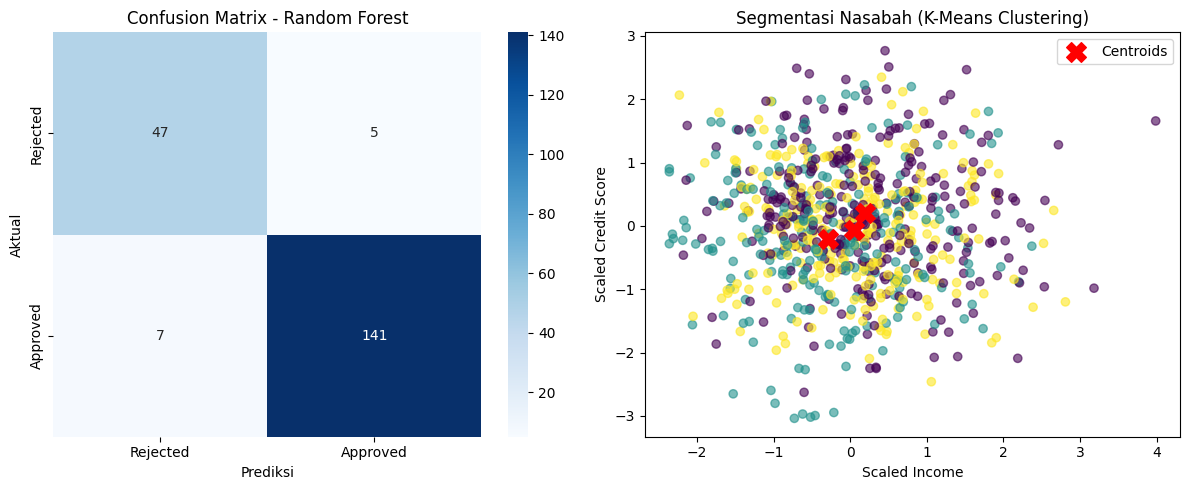

In [6]:
# ==========================================
# 5. VISUALISASI HASIL CLUSTER & CONFUSION MATRIX
# ==========================================
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
axes[0].set_title('Confusion Matrix - Random Forest')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Cluster Plot
axes[1].scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=clusters, cmap='viridis', alpha=0.6)
axes[1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='red', marker='X', label='Centroids')
axes[1].set_title('Segmentasi Nasabah (K-Means Clustering)')
axes[1].set_xlabel('Scaled Income')
axes[1].set_ylabel('Scaled Credit Score')
axes[1].legend()

plt.tight_layout()
plt.show()